<a href="https://colab.research.google.com/github/hernandez-figueroa/Metodos-Numericos-2/blob/main/Cuadratura_adaptable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#1f4e79">Cuadratura adaptable (Algoritmo 4.3)</h1>
<h3 style="color:#2e86c1">Análisis Numérico · Burden & Faires, sección 4.6</h3>

**Nombre:** Cristofer Alexander Hernandez FIgueroa_ &nbsp;&nbsp;

---

## 1. Problema y método

Se quiere calcular

$$I=\int_a^b f(x)\,dx$$

con un error menor que una tolerancia $TOL$, usando pocas evaluaciones de $f$.

**Idea:** usar pasos pequeños donde $f$ cambia mucho y pasos grandes donde cambia poco.

**Cómo funciona:**

1. Se calcula la regla de Simpson en todo el intervalo $[a,b]$:

$$S(a,b)=\frac{h}{3}\Big[f(a)+4f(a+h)+f(b)\Big],\qquad h=\frac{b-a}{2}$$

2. Se calcula Simpson en cada mitad: $S_1=S\left(a,\frac{a+b}{2}\right)$ y $S_2=S\left(\frac{a+b}{2},b\right)$.

3. Se compara,  
   Si

$$\big|S_1+S_2-S(a,b)\big|<10\,TOL$$

se acepta $S_1+S_2$ como aproximación en ese intervalo. (La teoría dice $15\,TOL$; en el libro se utiliza el $10\,TOL$ por seguridad.)

4. Si no se cumple, el intervalo se divide en dos mitades y se repite el proceso en cada una con tolerancia $TOL/2$.

5. La respuesta final es la suma de todas las aproximaciones aceptadas.

Para recordar qué intervalos faltan por revisar se usa una pila (una lista donde el último en entrar es el primero en salir).

In [31]:
import numpy as np                  # NumPy: sen, cos, arreglos
import matplotlib.pyplot as plt     # Matplotlib: gráficas

In [32]:
def cuadratura_adaptable(f, a, b, TOL, N):
    # Paso 1
    APP = 0
    h = (b - a) / 2
    FA = f(a)
    FC = f(a + h)
    FB = f(b)
    S = h * (FA + 4 * FC + FB) / 3     # Simpson para el intervalo completo

    # La pila es una lista []; cada elemento es una tupla () con los datos de un nivel:
    # (a, FA, FC, FB, h, TOL, S, L)
    pila = [(a, FA, FC, FB, h, 10 * TOL, S, 1)]
    evaluaciones = 3
    extremos = [b]                     # extremos de los subintervalos (para la gráfica)

    # Paso 2
    while len(pila) > 0:               # mientras la pila no esté vacía (i > 0)

        # Pasos 3 y 4: pop() toma el último nivel y lo borra de la pila
        ai, FAi, FCi, FBi, hi, TOLi, Si, Li = pila.pop()

        FD = f(ai + hi / 2)
        FE = f(ai + 3 * hi / 2)
        evaluaciones = evaluaciones + 2
        S1 = hi * (FAi + 4 * FD + FCi) / 6     # Simpson, mitad izquierda
        S2 = hi * (FCi + 4 * FE + FBi) / 6     # Simpson, mitad derecha

        # Paso 5
        if abs(S1 + S2 - Si) < TOLi:
            APP = APP + S1 + S2
            extremos.append(ai)
        else:
            if Li >= N:
                print("NIVEL EXCEDIDO")        # falla del procedimiento
                return None, extremos, evaluaciones
            # Añadir un nivel: datos de la mitad derecha
            pila.append((ai + hi, FCi, FE, FBi, hi / 2, TOLi / 2, S2, Li + 1))
            # Datos de la mitad izquierda (queda arriba, se revisa primero)
            pila.append((ai, FAi, FD, FCi, hi / 2, TOLi / 2, S1, Li + 1))

    # Paso 6
    return APP, extremos, evaluaciones

## 2. Prueba: ejemplo de la página 167

Se aproxima

$$\int_1^3 \frac{100}{x^2}\,\sin\!\left(\frac{10}{x}\right)dx \qquad \text{con } TOL=10^{-4}$$

**Resultado del libro:** $-1.426014$, con 23 subintervalos y 93 evaluaciones de la función.

**Valor exacto** (para calcular el error real): como $\dfrac{d}{dx}\left[10\cos\dfrac{10}{x}\right]=\dfrac{100}{x^2}\sin\dfrac{10}{x}$, entonces

$$I=10\left[\cos\frac{10}{3}-\cos 10\right]$$

In [33]:
def f(x):
    return (100 / x**2) * np.sin(10 / x)

APP, extremos, evaluaciones = cuadratura_adaptable(f, 1, 3, 1e-4, 50)

exacta = 10 * (np.cos(10 / 3) - np.cos(10))
error = abs(APP - exacta)
subintervalos = len(extremos) - 1

# f"...{x:.7f}" inserta una variable en el texto con 7 decimales
print(f"Aproximación (APP): {APP:.7f}    : -1.426014")
print(f"Valor exacto:       {exacta:.7f}")
print(f"Error real:         {error:.2e}       : 1.1e-05")
print(f"Subintervalos:      {subintervalos}    : 23")
print(f"Evaluaciones de f:  {evaluaciones}    : 93")

Aproximación (APP): -1.4260148    : -1.426014
Valor exacto:       -1.4260248
Error real:         9.95e-06       : 1.1e-05
Subintervalos:      23    : 23
Evaluaciones de f:  93    : 93


> **Nota:** en el libro escribe $-1.426014$ y el código da $-1.4260148\ldots$, que redondeado a 6 decimales es $-1.426015$. La diferencia es menor que $10^{-6}$: El número de subintervalos y de evaluaciones coincide exactamente.

### Gráfica

La función con los extremos de los 23 subintervalos (líneas rojas). Se ve cómo hay más subintervalos donde la función cambia más rápido (cerca de $x=1$).

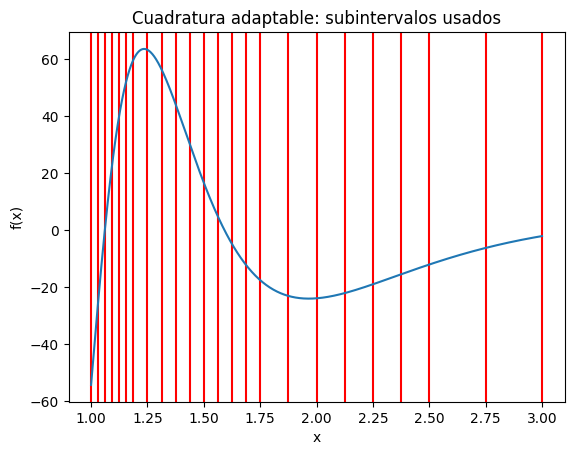

In [34]:
x = np.linspace(1, 3, 1000)

for e in extremos:
    plt.axvline(e, color="red")                # una línea vertical en cada extremo
plt.plot(x, f(x))
plt.title("Cuadratura adaptable: subintervalos usados")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()

In [35]:
resultado, _, _ = cuadratura_adaptable(f, 1, 3, 1e-4, 6)    # N pequeño: debe fallar
print("Con N = 6, resultado =", resultado)

NIVEL EXCEDIDO
Con N = 6, resultado = None


## 3. Solución final

$$\int_1^3 \frac{100}{x^2}\,\sin\!\left(\frac{10}{x}\right)dx \;\approx\; \boxed{-1.426015}$$

*(libro: $-1.426014$)*

<p style="color:#1e8449"><b>Error real ≈ 1.0×10⁻⁵, menor que TOL = 10⁻⁴, con 23 subintervalos y 93 evaluaciones de f.</b></p>

**Conclusión:** el algoritmo usó subintervalos pequeños donde la función cambia rápido y grandes donde es casi suave, y reprodujo los resultados del libro con solo 93 evaluaciones de la función.